# Datenanalyse Berliner Denkmalobjekte

In diesem Notebook werden beispielhaft online verfügbare Daten zu Berliner Denkmalobjekten analysiert.
Das Notebook wurde im November 2026 für den Workshops "KI und Denkmalpflege" (Organisation: ICOMOS) angelegt.
Teile des Notebooks wurden mittels der generativen KI M365 Copilot (GPT‑5 Chat Modell) von Microsoft im Modus "Unternehmesdatenschutz" erstellt.

Adrian Leander Pöllinger, Institut für Denkamlpflege und Bauforschung, ETH Zürich, November 2026

# Teil 1: Abfrage des öffentlichen Web Service

## Setup
Zu beginn werden die in der folge benötigten Python Biliotheken installiert

In [2]:
pip install geopandas matplotlib folium owslib

Note: you may need to restart the kernel to use updated packages.


Diese Bibliotheken werden anschliessend geladen

In [3]:
# Geodatenverarbeitung
import geopandas as gpd
import pandas as pd
import numpy as np

# Darstellung
import matplotlib.pyplot as plt

# Karten
import folium

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 200)

print("Bibliotheken geladen.")

Bibliotheken geladen.


## Berliner Denkmale laden
Nun können die Daten vom WebFeatureService Berlins geladen werden.
Je nach GeoServer-Version kann sich der Layername ändern. Deshalb fragen wir zunächst die verfügbaren Layer ab.

In [4]:
from owslib.wfs import WebFeatureService

WFS_URL = "https://gdi.berlin.de/services/wfs/denkmale"

wfs = WebFeatureService(
    url=WFS_URL,
    version="2.0.0"
)

print("Verfügbare Layer:")
for layer in list(wfs.contents):
    print(layer)

Verfügbare Layer:
denkmale:denkmale


### Gewünschten Layer laden

Der Layer denkmale:denkmale wird geladen und der Inhalt in eine eigene Datenbank (pandas dataframe) namens gdf gespeichert, so dass er in der folge im Notebook verfügbar ist.

In [5]:
url = (
    "https://gdi.berlin.de/services/wfs/denkmale"
    "?SERVICE=WFS"
    "&VERSION=2.0.0"
    "&REQUEST=GetFeature"
    "&TYPENAMES=denkmale:denkmale"
    "&OUTPUTFORMAT=application/json"
)

gdf = gpd.read_file(url)

print(len(gdf))
gdf.head()

9578


,gisid,id,link,typ,geometry
0,BAUD_09010001,09010001,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010001,Baudenkmal,"MULTIPOLYGON (((381106.385 5826097.953, 381106.387 5826097.953, 381116.18 5826099.604, 381116.18 5826099.604, 381117.708 5826099.861, 381117.716 5826099.873, 381115.334 5826114.078, 381112.553 582..."
1,BAUD_09010008,09010008,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010008,Baudenkmal,"MULTIPOLYGON (((395645.763 5814439.908, 395653.397 5814451.938, 395594.851 5814489.052, 395595.733 5814490.445, 395594.888 5814490.981, 395594.006 5814489.588, 395535.432 5814526.717, 395528.691 5..."
2,BAUD_09010009,09010009,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010009,Baudenkmal,"MULTIPOLYGON (((396452.601 5819434.486, 396456.842 5819435.83, 396456.74 5819436.079, 396462.817 5819438.005, 396459.776 5819447.603, 396456.414 5819446.538, 396455.942 5819448.028, 396448.416 581..."
3,BAUD_09010010,09010010,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010010,Baudenkmal,"MULTIPOLYGON (((396492.687 5819338.216, 396499.415 5819340.1, 396497.732 5819345.96, 396498.152 5819346.07, 396495.074 5819355.71, 396493.588 5819355.289, 396487.341 5819353.523, 396487.863 581935..."
4,BAUD_09010012,09010012,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010012,Baudenkmal,"MULTIPOLYGON (((396250.497 5819814.629, 396250.501 5819814.63, 396265.927 5819820.898, 396265.932 5819820.911, 396263.807 5819825.997, 396275.734 5819830.852, 396277.829 5819825.744, 396277.842 58..."


Die Quelle enthält zwei Identifikationsnummern, einen Link zur Denkmaldatenbank Berlins, den Denkmaltyp und die 2D-Geometry des Denkmals.

### Datenanalyse
Die Werte der einzelen Spalten lassen sich nun analysieren. Wir beginnen mit einer Übersicht der Denkmaltypen.

In [6]:
gdf["typ"].value_counts()

typ
Baudenkmal       7178
Gesamtanlage     1258
Gartendenkmal     564
Ensemble          511
Bodendenkmal       67
Name: count, dtype: int64

In [7]:
gdf.sample(10)[["gisid", "id", "typ", "link"]]

,gisid,id,typ,link
7177,BAUD_09097903,09097903,Baudenkmal,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09097903
8145,FLD_09045917,09045917,Gartendenkmal,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09045917
6317,BAUD_09090481,09090481,Baudenkmal,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09090481
2669,BAUD_09045630,09045630,Baudenkmal,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09045630
1839,BAUD_09031126,09031126,Baudenkmal,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09031126
9350,FLD_09085803,09085803,Gesamtanlage,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09085803
6150,BAUD_09090028,09090028,Baudenkmal,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09090028
5145,BAUD_09075763,09075763,Baudenkmal,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09075763
3083,BAUD_09050244,09050244,Baudenkmal,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09050244
1179,BAUD_09020292,09020292,Baudenkmal,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09020292


Räumliche Verteilung untersuchen

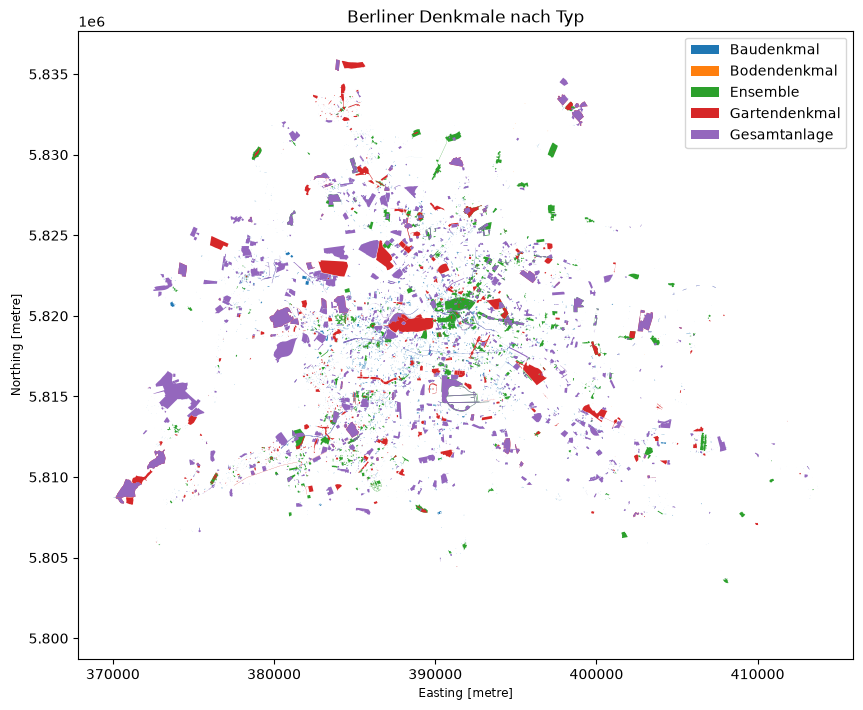

In [8]:
fig, ax = plt.subplots(figsize=(10, 10))

gdf.plot(
    column="typ",
    ax=ax,
    legend=True,
    markersize=2
)

ax.set_title("Berliner Denkmale nach Typ")

plt.show()

In [126]:
gdf["flaeche"] = gdf.geometry.area

gdf["flaeche"].describe()

count    9.578000e+03
mean     1.136792e+04
std      6.592947e+04
min      1.485627e+00
25%      2.919576e+02
50%      8.553693e+02
75%      3.940767e+03
max      2.739718e+06
Name: flaeche, dtype: float64

In [130]:
pip install rectpack

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for rectpack: filename=rectpack-0.2.2-py3-none-any.whl size=19373 sha256=4d0e446807397978061bcd7473ae2e8d41d680065d1c632c05b28dae69b81dea
  Stored in directory: /home/renku/.cache/pip/wheels/a0/39/c6/e088f7d582ebef64f5cc9138e5455e7fd86c48ac9dc51bc892
Successfully built rectpack
Note: you may need to restart the kernel to use updated packages.


In [9]:
from rectpack import newPacker
from shapely import affinity
import geopandas as gpd

# Fläche berechnen
packed = (
    gdf.assign(flaeche=gdf.geometry.area)
       .sort_values("flaeche", ascending=False)
       .head(500)
       .copy()
)

# Bounding-Boxen bestimmen
rects = []

for idx, geom in packed.geometry.items():

    minx, miny, maxx, maxy = geom.bounds

    width = maxx - minx
    height = maxy - miny

    rects.append(
        (
            idx,
            width,
            height,
            minx,
            miny
        )
    )

In [10]:
packer = newPacker(rotation=False)

for idx, width, height, _, _ in rects:
    packer.add_rect(width, height, rid=idx)

packer.add_bin(
    250000,   # Breite
    250000    # Höhe
)

packer.pack()

In [11]:
new_geoms = {}

for rect in packer.rect_list():

    bin_id, x, y, w, h, idx = rect

    geom = packed.loc[idx, "geometry"]

    minx, miny, maxx, maxy = geom.bounds

    moved = affinity.translate(
        geom,
        xoff=x - minx,
        yoff=y - miny
    )

    new_geoms[idx] = moved

packed["geometry"] = (
    packed.index.map(new_geoms)
)

packed = gpd.GeoDataFrame(
    packed,
    geometry="geometry",
    crs=gdf.crs
)

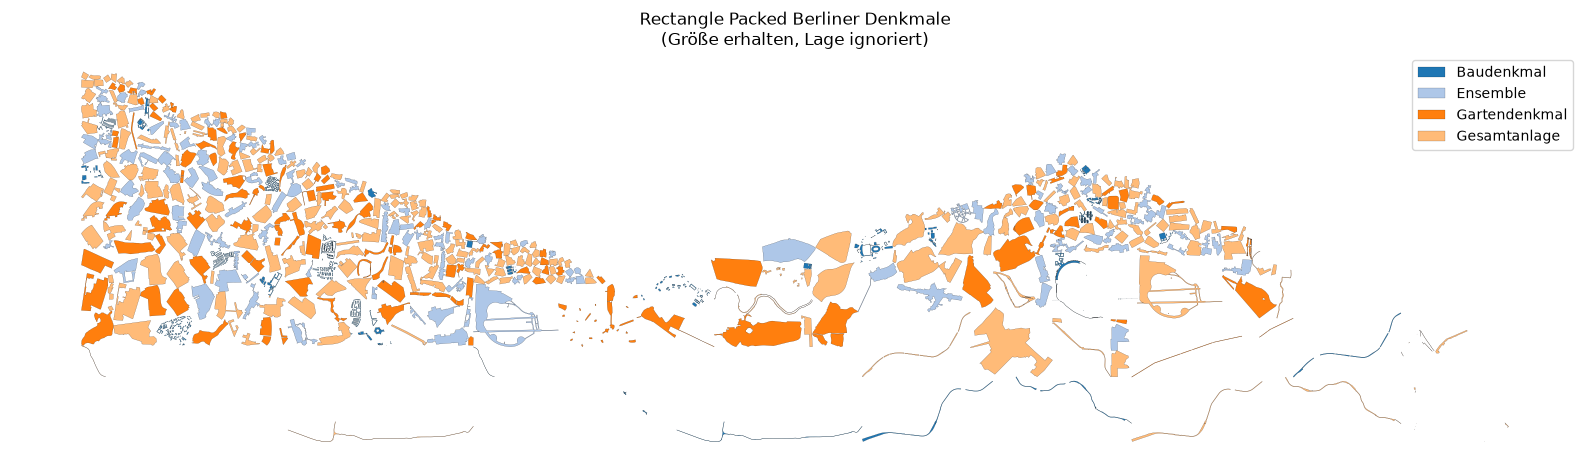

In [12]:
fig, ax = plt.subplots(figsize=(16,16))

packed.plot(
    ax=ax,
    column="typ",
    cmap="tab20",
    edgecolor="black",
    linewidth=0.1,
    legend=True
)

ax.set_axis_off()
ax.set_title(
    "Rectangle Packed Berliner Denkmale\n"
    "(Größe erhalten, Lage ignoriert)"
)

plt.tight_layout()
plt.show()

In [ ]:
from rectpack import newPacker
from shapely import affinity
import geopandas as gpd

# Fläche berechnen
packed = (
    gdf.copy()
       .assign(flaeche=gdf.geometry.area)
       .sort_values("flaeche", ascending=False)
       .reset_index(drop=True)
)

# Ursprüngliche Geometrien sichern
packed["geometry_original"] = packed.geometry

# Bounding-Boxen sammeln
packer = newPacker(rotation=False)

for idx, geom in enumerate(packed.geometry):

    minx, miny, maxx, maxy = geom.bounds

    width = maxx - minx
    height = maxy - miny

    width = max(width, 1)
    height = max(height, 1)

    packer.add_rect(
        width,
        height,
        rid=idx
    )

# Container
packer.add_bin(
    300000,
    300000
)

packer.pack()

# Zielgeometrien erzeugen
packed_geoms = [None] * len(packed)

for rect in packer.rect_list():

    _, x, y, w, h, idx = rect

    geom = packed.loc[idx, "geometry_original"]

    minx, miny, maxx, maxy = geom.bounds

    shifted = affinity.translate(
        geom,
        xoff=x - minx,
        yoff=y - miny
    )

    packed_geoms[idx] = shifted

packed["geometry_packed"] = packed_geoms

print("Packing erzeugt.")

In [ ]:
packed["cx0"] = packed.geometry_original.centroid.x
packed["cy0"] = packed.geometry_original.centroid.y

packed["cx1"] = packed.geometry_packed.apply(
    lambda g: g.centroid.x
)

packed["cy1"] = packed.geometry_packed.apply(
    lambda g: g.centroid.y
)

In [ ]:
from shapely import affinity

def interpolate_geometries(t):

    geoms = []

    for _, row in packed.iterrows():

        dx = (row.cx1 - row.cx0) * t
        dy = (row.cy1 - row.cy0) * t

        geoms.append(
            affinity.translate(
                row.geometry_original,
                xoff=dx,
                yoff=dy
            )
        )

    return geoms

In [ ]:
tmp = packed.copy()

tmp.geometry = interpolate_geometries(0.5)

fig, ax = plt.subplots(figsize=(14, 12))

tmp.plot(
    column="typ",
    cmap="tab20",
    ax=ax,
    legend=True,
    linewidth=0.1
)

ax.set_axis_off()

plt.show()

# Analyse Eintrag Datenbank

## Web Scraping
Hier werden die Einträge der Datenbank analysiert. Da diese nur in Form von Webseiten (html) vorliegen, können sie nicht direkt, sondern nur mittels so genanntem Web Scraping abgerufen werden. Diese Technik wird kritisch beurteilt, da sie beispielweise auch das massenhafte Sammeln personenbezogener Daten erlaubt. Bevor diese Technik eingesetzt wird, müssen daher die folgenden Punkte geprüft werden.

### Überprüfen von robot.txt

In [103]:
print(
    requests.get(
        "https://denkmaldatenbank.berlin.de/robots.txt"
    ).text
)

User-agent: *



Erscheint hier nach "User-agent: *", "Disallow" kann dies bedeuten, dass die Daten nicht via Scraping abgerufen werden dürfen.

### Autorenschaft der Abfrage hinterlegen

Bei der Abfrage werden Angaben zur Autorenschaft hinterlegt, so dass eine Web-Administrator die Abfragenden kontaktieren kann.
    z.B.: User-Agent": "IDB ETH Zurich Data Research Bot (poellinger@arch.ethz.ch)

### Sparsame Datenabfrage

Es werden nur die benötigten Daten und nicht die gesamten Seiten heruntergeladen.

## Datenabruf

In [39]:
pip install 

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [bs4]
Note: you may need to restart the kernel to use updated packages.


### Einen Beispieleintrag ansehen

In [106]:
import requests
from bs4 import BeautifulSoup

url = "https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09097785"

response = requests.get(
    url,
    headers={
        "User-Agent": "ETH Zurich Data Research Bot (poellinger@arch.ethz.ch)"
    }
)

soup = BeautifulSoup(response.text, "html.parser")

table = soup.find("table")  # erste Tabelle

print(table.get_text("\n", strip=True))

Obj.-Dok.-Nr.
09097785
Bezirk
Friedrichshain-Kreuzberg
Ortsteil
Kreuzberg
Adressen
Charlottenstraße 96, 97, 97A, 97B
Denkmalart
Baudenkmal
Sachbegriff
Wohnanlage & Mietshaus
Datierung
1986-1988
Entwurf
Hejduk, John (Architekt)
Bauherr
Katz KG im Erbbaurecht des Landes Berlin


## Ersten 1000 Denkmale

In [76]:
pip install tqdm

Note: you may need to restart the kernel to use updated packages.


### URLs der ersten 1000 Denkmale

In [79]:
sample = gdf.head(1000).copy()

print(len(sample))
sample[["link", "typ"]].head()

1000


,link,typ
0,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010001,Baudenkmal
1,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010008,Baudenkmal
2,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010009,Baudenkmal
3,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010010,Baudenkmal
4,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09010012,Baudenkmal


### Hilfsfunktion zum Abrufen und Parsen

In [109]:
import re
import requests
import pandas as pd
from bs4 import BeautifulSoup
from tqdm import tqdm

session = requests.Session()
session.headers.update({
    "User-Agent": "Mozilla/5.0"
})


def extract_denkmal_metadata(url):

    try:

        r = session.get(url, timeout=15)

        if r.status_code != 200:
            return None

        soup = BeautifulSoup(r.text, "html.parser")

        table = soup.find("table")

        if table is None:
            return None

        record = {
            "url": url
        }

        for row in table.find_all("tr"):

            cells = row.find_all(["td", "th"])

            if len(cells) != 2:
                continue

            key = cells[0].get_text(" ", strip=True)
            value = cells[1].get_text(" ", strip=True)

            record[key] = value

        return record

    except Exception as e:
        print(f"Fehler bei {url}: {e}")
        return None

### Detailseiten einlesen

In [110]:
records = []

for url in tqdm(sample["link"]):

    r = extract_denkmal_metadata(url)

    if r is not None:
        records.append(r)

df = pd.DataFrame(records)

100%|██████████| 1000/1000 [00:46<00:00, 21.59it/s]


Datierung prüfen

In [111]:
cols = [
    c for c in [
        "Bezirk",
        "Sachbegriff",
        "Datierung",
        "url"
    ]
    if c in df.columns
]

df.sort_values("Datierung")[cols].head(20)

,Bezirk,Sachbegriff,Datierung,url
356,Reinickendorf,Kirche ev. & Dorfanger,1401/1599,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09011650
432,Reinickendorf,Kirche ev.,1486/1500,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09011769
408,Reinickendorf,Kirche,1486/1500,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09011732
348,Reinickendorf,Schloss & Gutshaus,1501/1600,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09011641
108,Mitte,Wohnhaus & Marstall,1624,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09011239
107,Mitte,Marstall,1666-1670,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09011238
117,Mitte,Kirche & Kirchplatz,1695-1705,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09011257
127,Mitte,Wohnhaus,1701-1704,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09011275
175,Mitte,Kirche ev.,1712-1713,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09011358
383,Reinickendorf,Wohnhaus,1746/1755,https://denkmaldatenbank.berlin.de/daobj.php?obj_dok_nr=09011694


In [112]:
def erstes_baujahr(datierung):

    if pd.isna(datierung):
        return None

    match = re.search(r"(\d{4})", str(datierung))

    if match:
        return int(match.group(1))

    return None

df["baujahr"] = df["Datierung"].apply(erstes_baujahr)

In [113]:
cols = [
    c for c in [
        "baujahr",
        "Datierung",
    ]
    if c in df.columns
]

df.sort_values("Datierung")[cols].head(20)

,baujahr,Datierung
356,1401.0,1401/1599
432,1486.0,1486/1500
408,1486.0,1486/1500
348,1501.0,1501/1600
108,1624.0,1624
107,1666.0,1666-1670
117,1695.0,1695-1705
127,1701.0,1701-1704
175,1712.0,1712-1713
383,1746.0,1746/1755


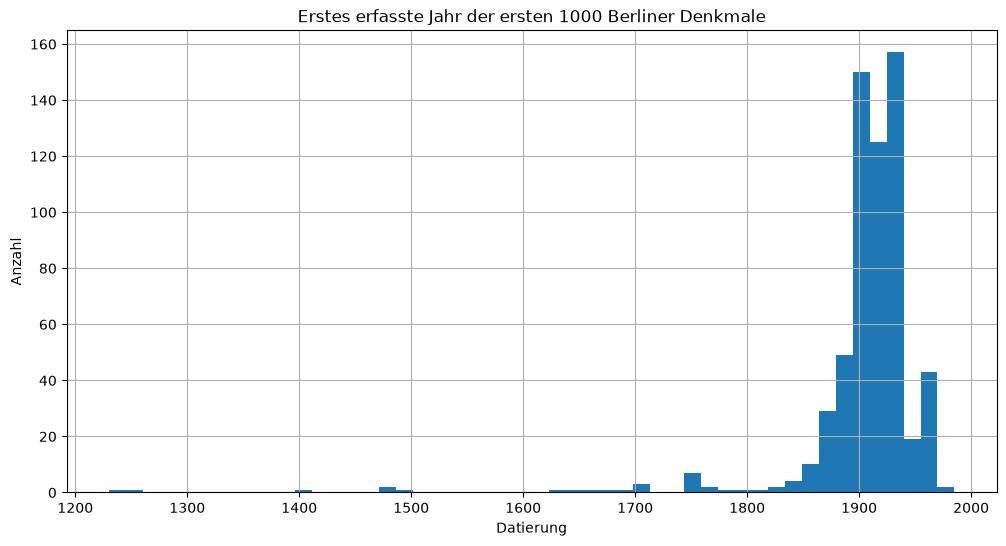

In [114]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

df["baujahr"].dropna().hist(
    bins=50
)

plt.xlabel("Datierung")
plt.ylabel("Anzahl")
plt.title("Erstes erfasste Jahr der ersten 1000 Berliner Denkmale")

plt.show()